# 6. Policy analysis and building context

Which rule for choosing tracts reaches the most severely burdened households, and how much would a
cost cut in the priority tracts help? Counts use LEAD household groups. The last section uses the
City's Energy Benchmarking data on large multifamily buildings as context.
Scripts: `scripts/10_policy.py`, `scripts/11_figures.py`, `scripts/12_benchmarking.py`.

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


In [2]:
display(Markdown((T / "policy_summary.md").read_text()))

# Policy analysis

- Sample: 1,054,210 households; 281,461 in groups above 6% and 164,186 above 10%.
- Priority tracts (high-burden clusters): 175 tracts, 177,342 households.
- Serving the same number of households, the rule that reaches the most severely burdened households (excluding the benchmark) is **Lowest median income**: 62,574 (38.1% of the city's), versus 58,894 for the clusters and 62,998 for the benchmark.
- A 20% cost cut for every household in the priority tracts lowers their burden from 5.43% to 4.34% and moves 16,454 households below 6% (9,934 below 10%), saving about $606 per household per year.
- The same cut limited to the 127,037 low-income households there moves 15,269 below 6% and lowers their burden from 9.54% to 7.63%.

_Counts use LEAD household-group averages, so they approximate how many households cross each line._


In [3]:
pd.read_csv(T / "policy_targeting.csv").round(3)

,budget,rule,tracts,households,hh_above_10,share_of_city_above_10,hh_above_6,share_of_city_above_6,precision_above_10,low_income_hh,overlap_with_clusters
0,Same number of tracts,High-burden clusters (LISA),175,177342.133,58893.984,0.359,93905.499,0.334,0.332,127037.488,175
1,Same number of tracts,Lowest median income,175,182672.665,64163.491,0.391,97459.533,0.346,0.351,140645.721,105
2,Same number of tracts,Highest poverty rate,175,187611.355,61036.655,0.372,92489.528,0.329,0.325,138092.054,92
3,Same number of tracts,Highest measured burden (benchmark),175,178520.313,63191.413,0.385,100366.345,0.357,0.354,133417.897,131
4,Same number of households,High-burden clusters (LISA),175,177342.133,58893.984,0.359,93905.499,0.334,0.332,127037.488,175
5,Same number of households,Lowest median income,170,177590.875,62573.942,0.381,94902.776,0.337,0.352,136852.595,103
6,Same number of households,Highest poverty rate,166,178000.269,57419.428,0.350,87092.802,0.309,0.323,130807.774,86
7,Same number of households,Highest measured burden (benchmark),174,177891.773,62998.383,0.384,100088.918,0.356,0.354,132951.717,131


In [4]:
pd.read_csv(T / "policy_scenarios.csv").round(2)

,who,cost_cut,households_served,burden_before,burden_after,li_burden_before,li_burden_after,above_6_before,above_6_after,dropped_below_6,above_10_before,above_10_after,dropped_below_10,city_above_6_before,city_above_6_after,annual_savings_total,annual_savings_per_served_hh
0,All households,0.1,177342.13,5.43,4.88,9.54,8.59,93905.5,84821.91,9083.59,58893.98,53881.07,5012.91,281460.95,272377.36,5.3717e+07,302.90
1,All households,0.2,177342.13,5.43,4.34,9.54,7.63,93905.5,77451.65,16453.85,58893.98,48959.60,9934.38,281460.95,265007.10,1.0743e+08,605.80
2,All households,0.3,177342.13,5.43,3.80,9.54,6.68,93905.5,68359.36,25546.14,58893.98,43530.68,15363.30,281460.95,255914.81,1.6115e+08,908.71
3,Low-income households (<80% AMI) only,0.1,127037.49,5.43,5.06,9.54,8.59,93905.5,85511.78,8393.72,58893.98,53962.48,4931.51,281460.95,273067.23,3.6305e+07,285.78
4,Low-income households (<80% AMI) only,0.2,127037.49,5.43,4.69,9.54,7.63,93905.5,78636.36,15269.14,58893.98,49134.38,9759.61,281460.95,266191.81,7.2610e+07,571.56
5,Low-income households (<80% AMI) only,0.3,127037.49,5.43,4.33,9.54,6.68,93905.5,69969.52,23935.98,58893.98,43761.63,15132.36,281460.95,257524.97,1.0891e+08,857.34


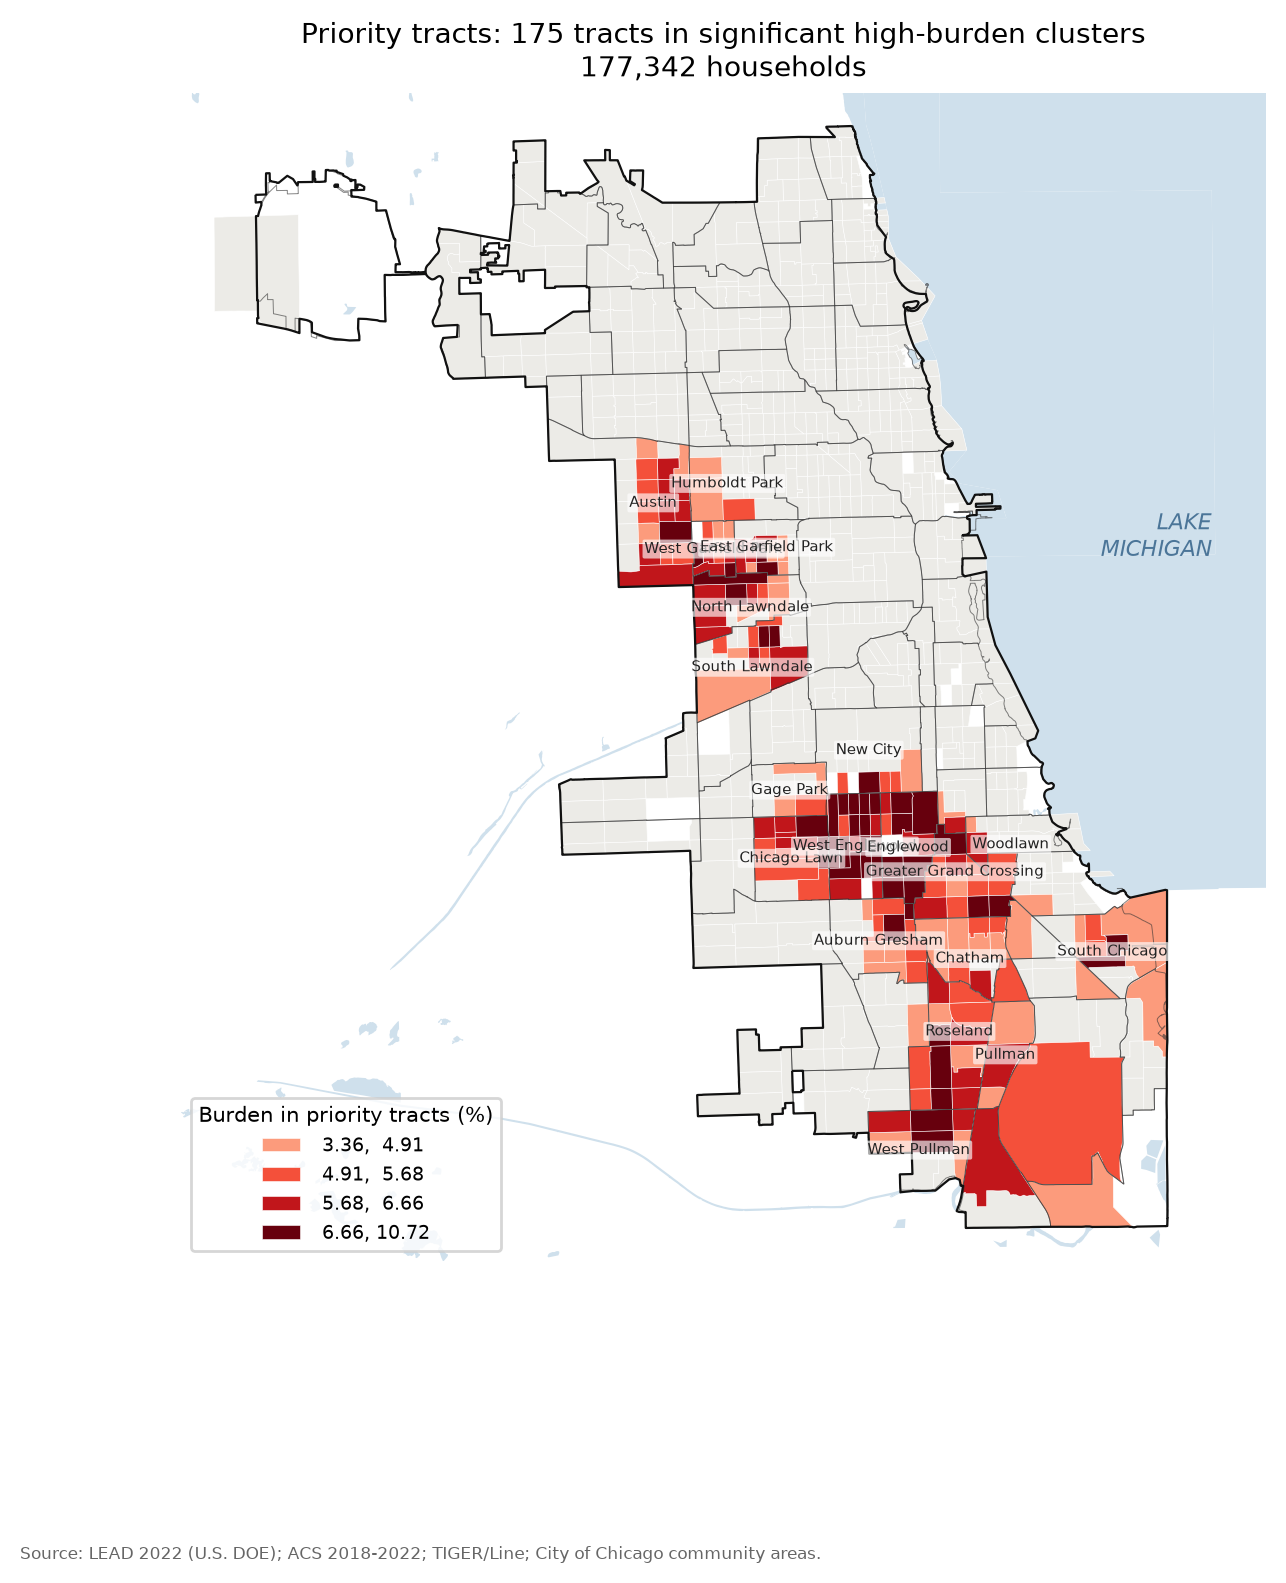

In [5]:
display(Image(F / "map_priority.png", width=560))

In [6]:
pd.read_csv(T / "priority_by_community_area.csv").head(15)

,community_area,tracts,households
0,Austin,16,20883.2633
1,Chicago Lawn,10,15161.5056
2,Roseland,13,13364.7193
3,Chatham,8,12994.4119
4,Greater Grand Crossing,12,11966.2539
5,South Lawndale,10,10781.9975
6,Auburn Gresham,10,10262.7195
7,West Englewood,18,9149.2999
8,North Lawndale,10,8933.7523
9,Englewood,10,7673.2170


## Energy Benchmarking: large multifamily buildings

In [7]:
b = json.loads((T / "benchmarking_summary.json").read_text())
display(pd.Series({k: v for k, v in b.items() if not isinstance(v, dict)}).to_frame("value"))
for f in ["benchmarking_by_cluster.csv", "benchmarking_by_era.csv"]:
    if (T / f).exists(): display(pd.read_csv(T / f).round(1))

,value
data_year,2023
multifamily_buildings,1262
tracts_with_buildings,416
median_site_eui_high_burden_clusters,71.6
median_site_eui_elsewhere,69.5
buildings_in_high_burden_clusters,121
mann_whitney_p,0.1649
tracts_with_3plus_buildings,131
spearman_tract_eui_vs_burden,0.116
note,"Buildings of about 50,000 sq ft and up only; s..."


,cluster,buildings,median_site_eui,median_gas_kbtu_per_sqft
0,High-High,121,71.6,48.1
1,Low-Low,740,69.6,48.9
2,Not significant,401,68.7,47.5


,era,buildings,median_site_eui,median_gas_kbtu_per_sqft
0,Before 1950,352,71.6,55.9
1,1950-1979,342,79.5,62.6
2,1980 or later,568,62.8,37.5
